# Phase 6 â€” Visualization & Writeup

Produces all figures for the paper/report:
1. **UMAP** of early-fusion embedding space (2,075 multimodal tracks)
2. **Cross-genre emotional twin gallery** â€” same-quadrant retrievals across different genres
3. **Emotional paradox gallery** â€” top-15 tracks where audio emotion â‰  lyric emotion
4. **Ablation table** â€” all fusion strategies Ã— both split schemes
5. **Precision@K curves** â€” paper-quality figure

In [39]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize as MplNorm
from matplotlib.cm import ScalarMappable
import faiss
import warnings
warnings.filterwarnings('ignore')

from umap import UMAP

# ── paths ──────────────────────────────────────────────────────────────────
import os; ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUTPUTS     = ROOT + r'\outputs'
FAISS_DIR   = OUTPUTS + r'\faiss_index'

# ── style ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 150,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

Q_COLORS = {1: '#F4A261', 2: '#E63946', 3: '#457B9D', 4: '#2A9D8F'}
Q_LABELS = {1: 'Q1 Happy/Excited', 2: 'Q2 Angry/Tense',
             3: 'Q3 Sad/Depressed', 4: 'Q4 Calm/Relaxed'}

print('Imports OK')

Imports OK


## Load data

In [40]:
# ── master dataset ─────────────────────────────────────────────────────────
meta_df = pd.read_parquet(OUTPUTS + r'\merged_dataset.parquet')
meta_df['quadrant'] = meta_df['quadrant'].astype(str).str.replace('Q', '', regex=False).astype(int)

# ── audio features ────────────────────────────────────────────────────────
audio_df = pd.read_parquet(OUTPUTS + r'\audio_features.parquet')
clap_arr     = np.vstack(audio_df['audio_clap'].values).astype(np.float32)
clap_raw_arr = np.vstack(audio_df['audio_clap_raw'].values).astype(np.float32)
audio_sid_idx = {sid: i for i, sid in enumerate(audio_df['song_id'])}

# ── lyrics features ───────────────────────────────────────────────────────
lyrics_df  = pd.read_parquet(OUTPUTS + r'\lyrics_features.parquet')
sbert_arr     = np.vstack(lyrics_df['lyrics_sbert'].values).astype(np.float32)
sbert_raw_arr = np.vstack(lyrics_df['lyrics_sbert_raw'].values).astype(np.float32)
lyrics_sid_idx = {sid: i for i, sid in enumerate(lyrics_df['song_id'])}

# ── coherence scores ──────────────────────────────────────────────────────
coh_df = pd.read_parquet(OUTPUTS + r'\coherence_scores.parquet')

# ── ablation results ──────────────────────────────────────────────────────
abl_df = pd.read_csv(OUTPUTS + r'\ablation_table.csv')

# ── multimodal song IDs (tracks with both audio + lyrics) ─────────────────
mm_df = meta_df[meta_df['is_multimodal']].copy().reset_index(drop=True)
mm_sids = mm_df['song_id'].tolist()

# ── build aligned arrays for mm tracks ───────────────────────────────────
mm_clap_raw  = np.vstack([clap_raw_arr[audio_sid_idx[s]] for s in mm_sids]).astype(np.float32)
mm_sbert_raw = np.vstack([sbert_raw_arr[lyrics_sid_idx[s]] for s in mm_sids]).astype(np.float32)
mm_early_raw = np.hstack([mm_clap_raw, mm_sbert_raw])  # (2075, 1280) un-normalized

# L2-normalize for FAISS cosine similarity
def l2_norm(v):
    norms = np.linalg.norm(v, axis=1, keepdims=True)
    return (v / norms).astype(np.float32)

mm_early_normed = l2_norm(mm_early_raw)

print(f'Multimodal tracks : {len(mm_sids)}')
print(f'Early-fusion shape: {mm_early_raw.shape}')
print(f'Coherence rows    : {len(coh_df)}')
print(f'Ablation rows     : {len(abl_df)}')

Multimodal tracks : 2075
Early-fusion shape: (2075, 1280)
Coherence rows    : 2075
Ablation rows     : 32


## 1  UMAP of joint embedding space

In [41]:
print('Fitting UMAP (n_neighbors=30, min_dist=0.1) on early-fusion vectors ...')
reducer = UMAP(n_neighbors=30, min_dist=0.1, n_components=2, metric='cosine',
               random_state=42, verbose=False)
embedding = reducer.fit_transform(mm_early_normed)   # (2075, 2)
print(f'UMAP done â€” shape {embedding.shape}')

Fitting UMAP (n_neighbors=30, min_dist=0.1) on early-fusion vectors ...
UMAP done â€” shape (2075, 2)


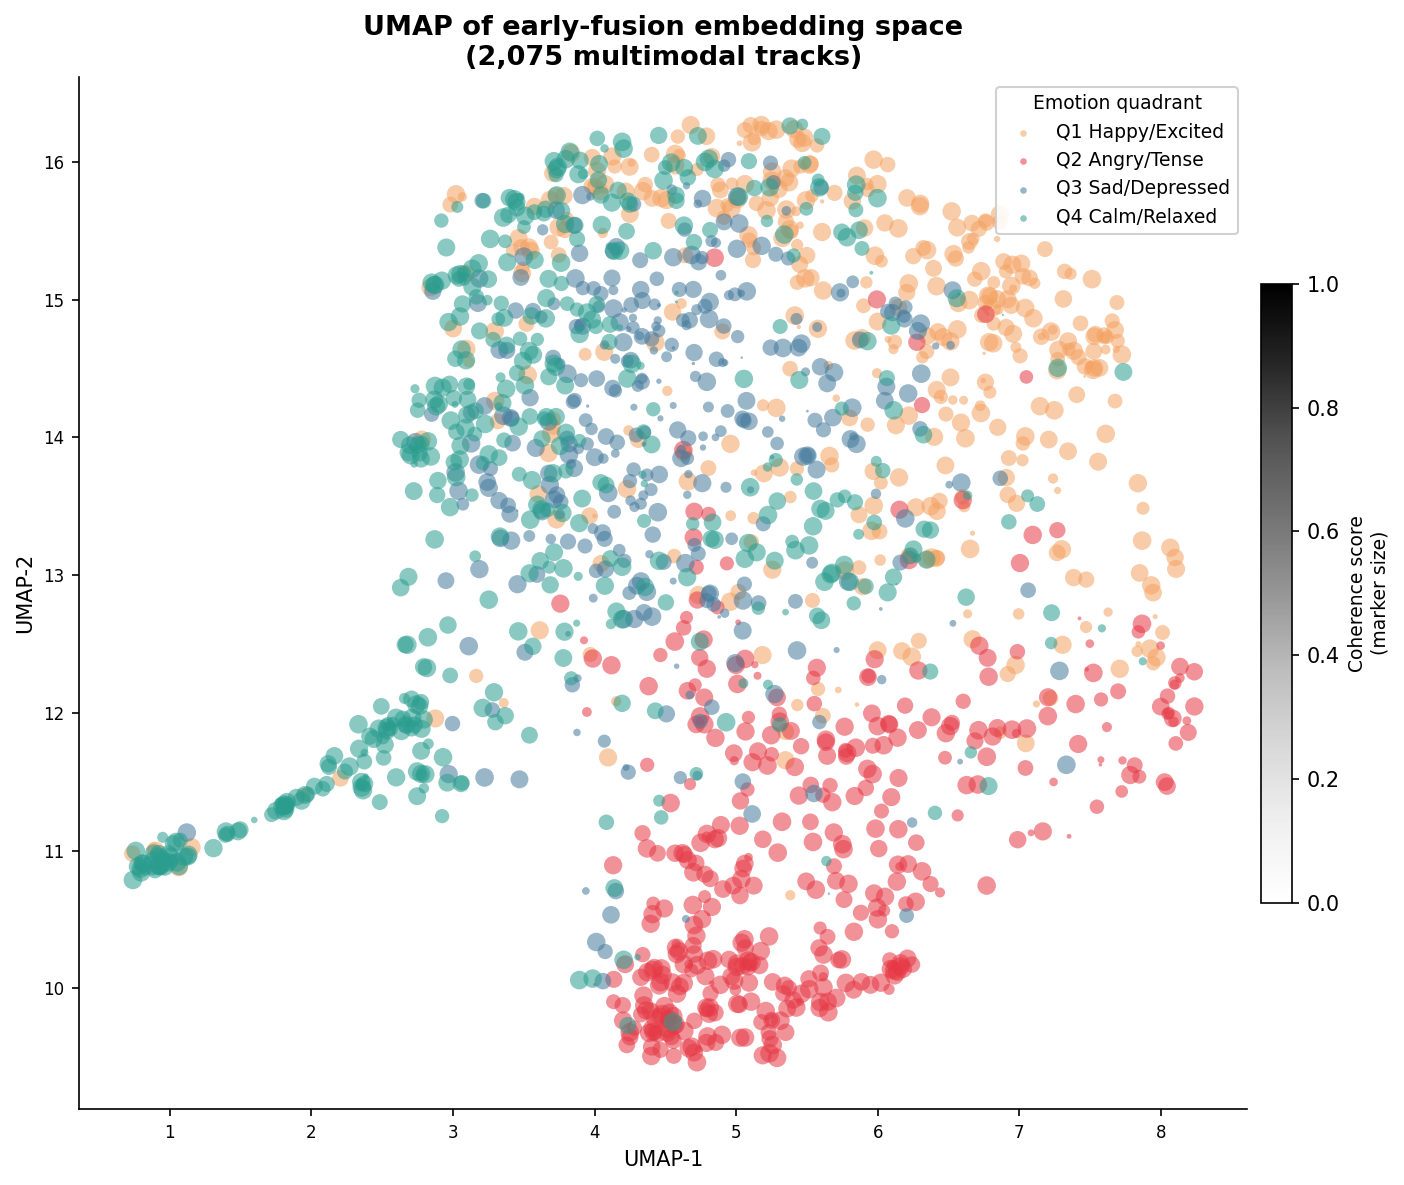

Saved umap_joint_space.png


In [42]:
# Merge coherence scores onto mm_df
mm_plot = mm_df.merge(coh_df[['song_id', 'coherence_score']], on='song_id', how='left')
mm_plot['umap_x'] = embedding[:, 0]
mm_plot['umap_y'] = embedding[:, 1]

coh_vals = mm_plot['coherence_score'].fillna(0.5).values
# marker size: coherence 0â†’1  maps to size 10â†’80
marker_sizes = 10 + 70 * coh_vals

fig, ax = plt.subplots(figsize=(10, 8))

for q in [1, 2, 3, 4]:
    mask = mm_plot['quadrant'] == q
    ax.scatter(
        mm_plot.loc[mask, 'umap_x'],
        mm_plot.loc[mask, 'umap_y'],
        s=marker_sizes[mask],
        c=Q_COLORS[q],
        alpha=0.55,
        linewidths=0,
        label=Q_LABELS[q],
    )

# coherence colorbar via proxy
sm = ScalarMappable(cmap='Greys', norm=MplNorm(vmin=0, vmax=1))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.01)
cbar.set_label('Coherence score\n(marker size)', fontsize=9)

legend = ax.legend(title='Emotion quadrant', fontsize=9, title_fontsize=9,
                   loc='upper right', framealpha=0.9)
ax.set_title('UMAP of early-fusion embedding space\n(2,075 multimodal tracks)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('UMAP-1', fontsize=10)
ax.set_ylabel('UMAP-2', fontsize=10)
ax.tick_params(labelsize=8)

plt.tight_layout()
fig.savefig(OUTPUTS + r'\umap_joint_space.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved umap_joint_space.png')

## 2  Cross-genre emotional twin gallery

In [43]:
# Load early-fusion FAISS index
import faiss
early_index = faiss.read_index(FAISS_DIR + r'\early_fusion.index')
early_meta  = pd.read_parquet(FAISS_DIR + r'\early_fusion_meta.parquet')
early_sid   = early_meta['song_id'].tolist()
early_idx   = {sid: i for i, sid in enumerate(early_sid)}

# Build a lookup: song_id â†’ (genres list, quadrant, artist, title)
meta_lookup = meta_df.set_index('song_id')[['artist', 'title', 'quadrant', 'genres']].to_dict('index')

def parse_genres(g):
    """Return set of genre strings from a stored genres field."""
    if g is None or (isinstance(g, float) and np.isnan(g)):
        return set()
    if isinstance(g, (list, np.ndarray)):
        return set(str(x).strip().lower() for x in g)
    return set(str(g).strip().lower().split(','))

def retrieve_top_k(query_sid, k=20):
    """Return top-k song_ids by early-fusion cosine similarity (excluding query)."""
    qi = early_idx[query_sid]
    qv = mm_early_normed[mm_sids.index(query_sid):mm_sids.index(query_sid)+1]
    _, I = early_index.search(qv, k + 1)
    return [early_sid[j] for j in I[0] if early_sid[j] != query_sid][:k]

def find_cross_genre_twin(query_sid, top_k=50):
    """Find nearest neighbour in same quadrant with disjoint genre set."""
    q_genres = parse_genres(meta_lookup[query_sid]['genres'])
    q_quad   = meta_lookup[query_sid]['quadrant']
    for candidate in retrieve_top_k(query_sid, k=top_k):
        if candidate not in meta_lookup:
            continue
        c_quad   = meta_lookup[candidate]['quadrant']
        c_genres = parse_genres(meta_lookup[candidate]['genres'])
        if c_quad == q_quad and q_genres.isdisjoint(c_genres) and len(c_genres) > 0:
            return candidate
    return None

# Pick 2 anchor seeds per quadrant from multimodal tracks
seeds = {}
for q in [1, 2, 3, 4]:
    q_sids = [s for s in mm_sids if meta_lookup[s]['quadrant'] == q]
    seeds[q] = q_sids[:8]   # candidates to try

pairs = []
for q in [1, 2, 3, 4]:
    found = 0
    for anchor in seeds[q]:
        twin = find_cross_genre_twin(anchor)
        if twin:
            pairs.append((q, anchor, twin))
            found += 1
            if found == 2:
                break

print(f'Found {len(pairs)} cross-genre twin pairs')
for q, a, t in pairs:
    ag = parse_genres(meta_lookup[a]['genres'])
    tg = parse_genres(meta_lookup[t]['genres'])
    print(f"  Q{q}  [{', '.join(sorted(ag))}] {meta_lookup[a]['artist']} â€” {meta_lookup[a]['title']}")
    print(f"    â†” [{', '.join(sorted(tg))}] {meta_lookup[t]['artist']} â€” {meta_lookup[t]['title']}")

Found 8 cross-genre twin pairs
  Q1  [adult contemporary, contemporary pop/rock, pop/rock, r&b, urban] Lionel Richie â€” All Night Long (All Night)
    â†” [electronic] Paul Oakenfold â€” Starry Eyed Surprise
  Q1  [club/dance, contemporary pop/rock, dance-pop, disco, funk, pop/rock, r&b, urban] Kool & the Gang â€” Celebration
    â†” [easy listening, vocal] The Andrews Sisters â€” Beer Barrel Polka
  Q2  [british metal, heavy metal, new wave of british heavy metal, pop/rock] Iron Maiden â€” Aces High
    â†” [electronic] Atari Teenage Riot â€” Get Up While You Can
  Q2  [electronic, pop/rock] Five Finger Death Punch â€” Ashes
    â†” [rap] Ice-T â€” Colors
  Q3  [adult alternative pop/rock, alternative/indie rock, pop/rock] Gary Jules â€” Mad World
    â†” [blues, r&b] Jimmy Reed â€” I Was So Wrong
  Q3  [adult alternative pop/rock, alternative pop/rock, alternative/indie rock, contemporary pop/rock, pop/rock] Ben Folds Five â€” Brick
    â†” [country] Toby Keith â€” Upstairs Downtown

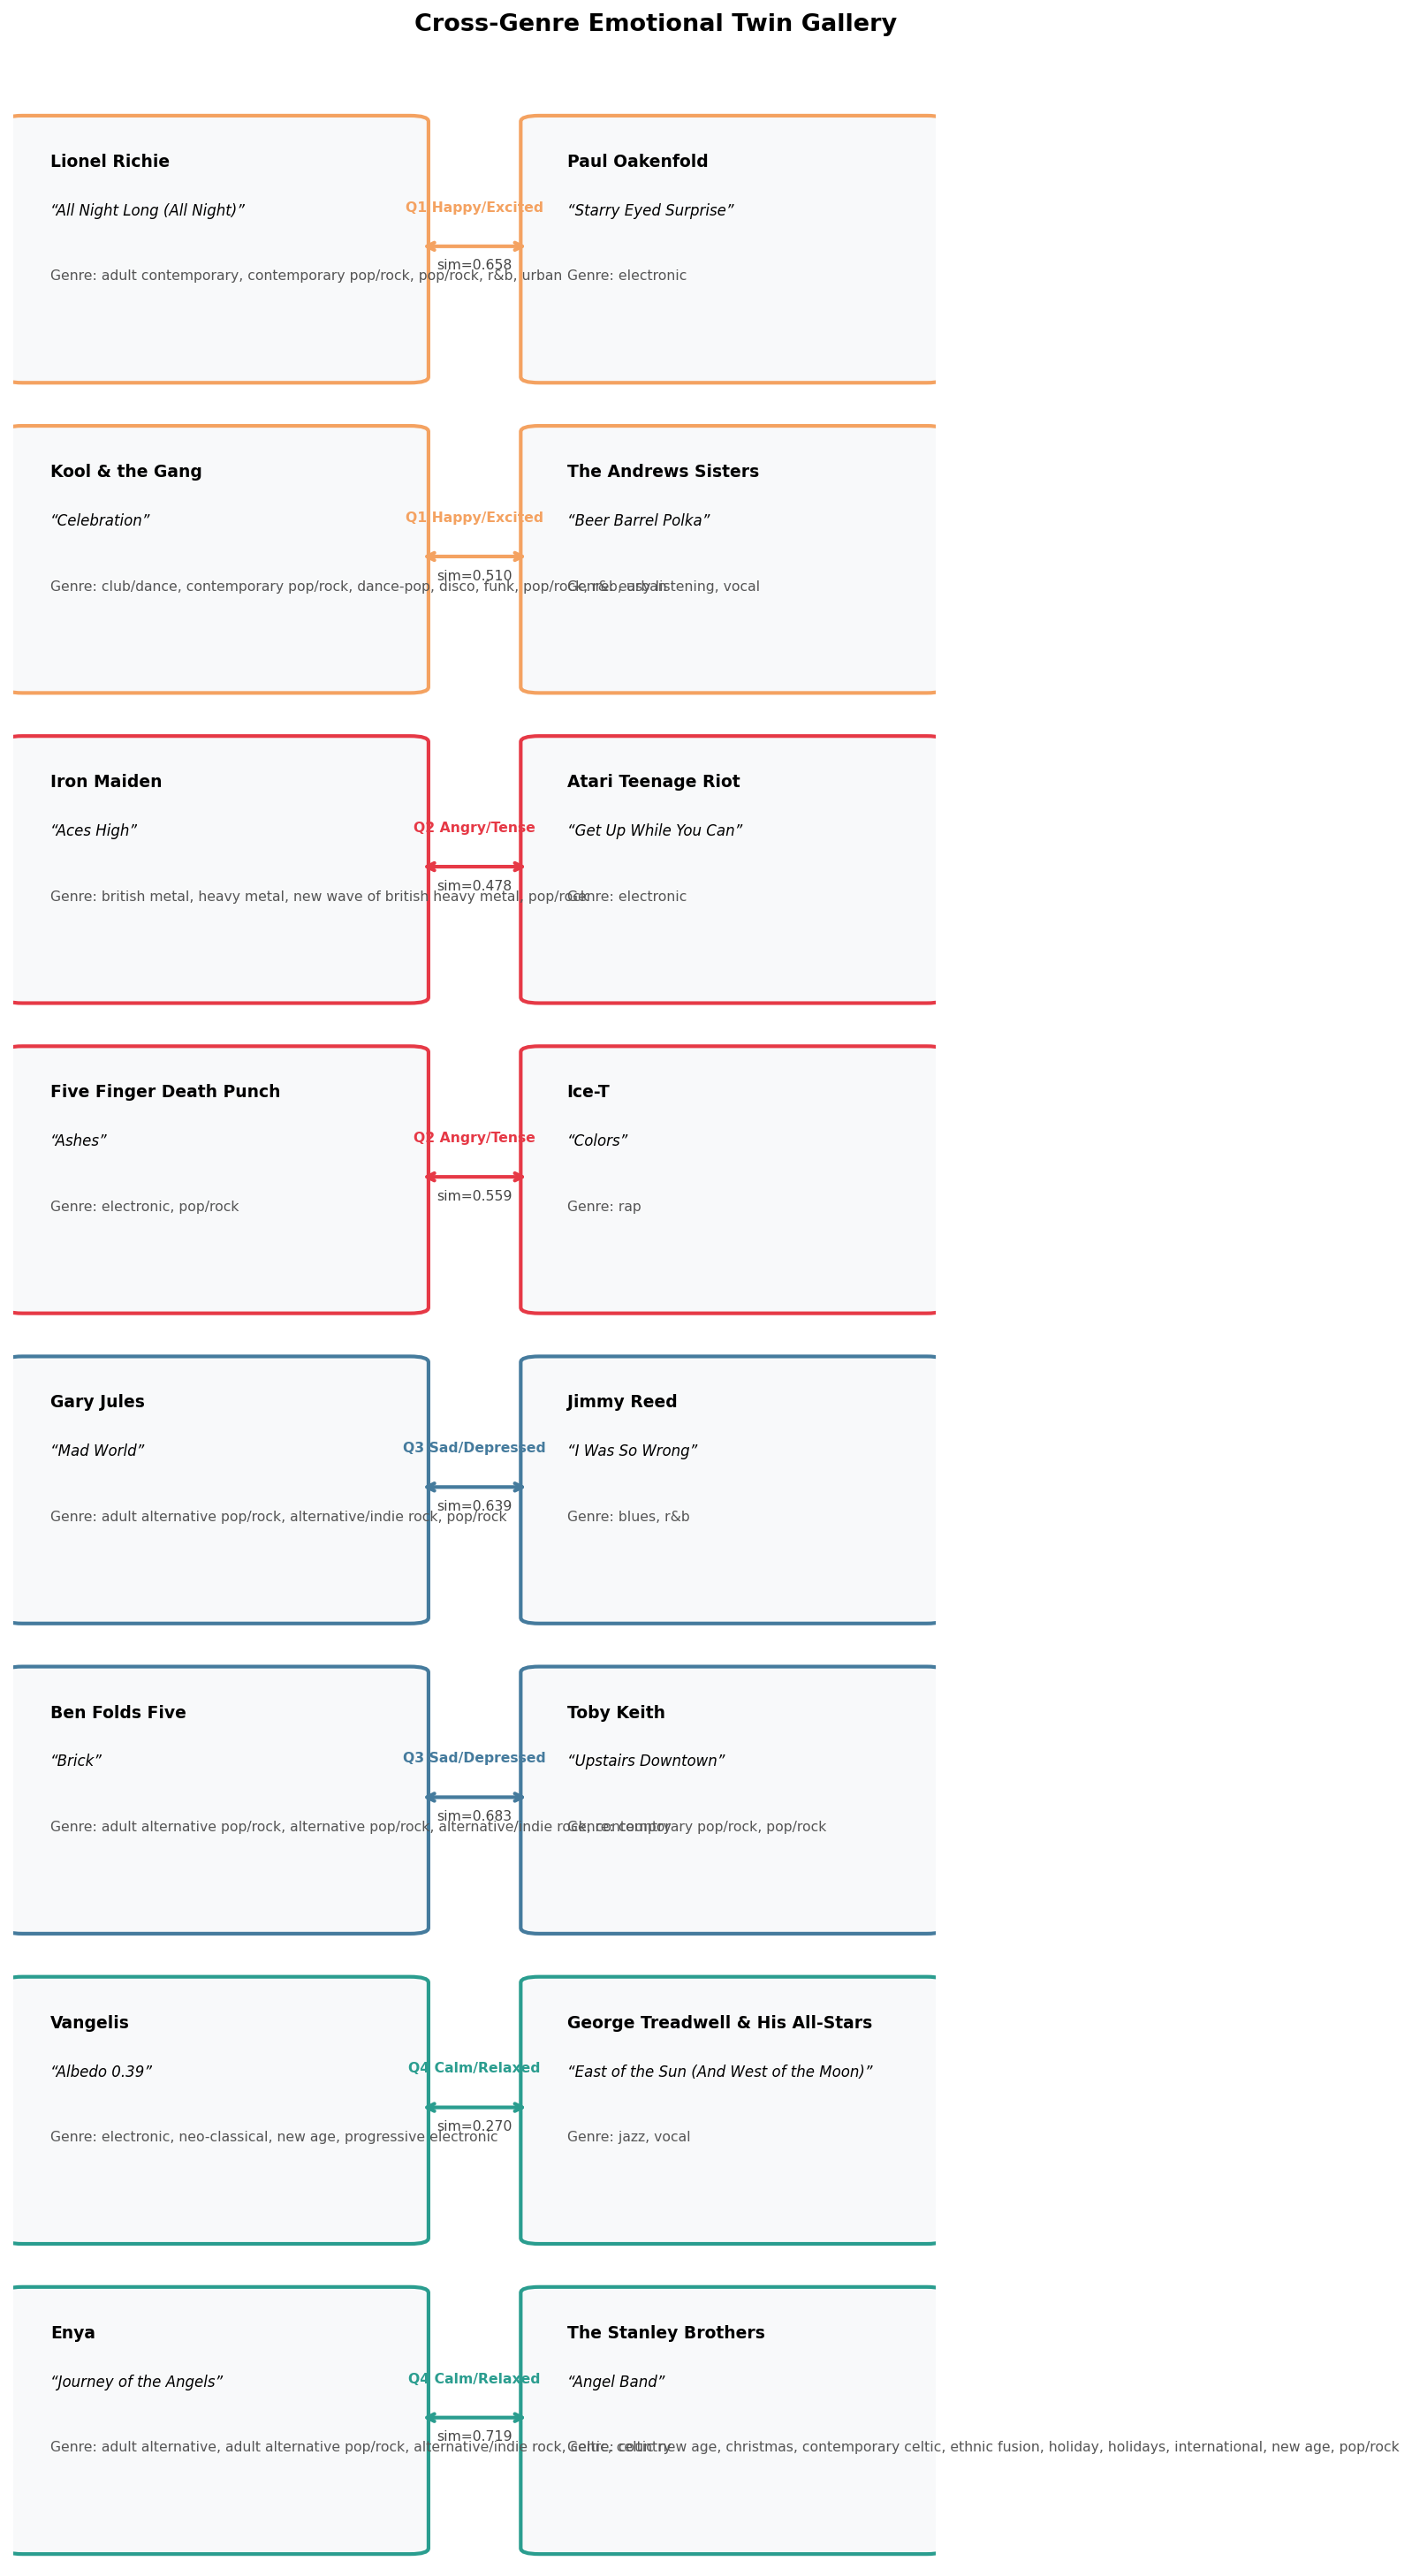

Saved cross_genre_gallery.png


In [44]:
# ── Gallery figure ────────────────────────────────────────────────────────
n_pairs = len(pairs)
fig, axes = plt.subplots(n_pairs, 1, figsize=(10, 2.4 * n_pairs))
if n_pairs == 1:
    axes = [axes]

for ax, (q, anchor, twin) in zip(axes, pairs):
    am = meta_lookup[anchor]
    tm = meta_lookup[twin]
    ag = ', '.join(sorted(parse_genres(am['genres']))) or 'unknown'
    tg = ', '.join(sorted(parse_genres(tm['genres']))) or 'unknown'

    # compute similarity score
    a_idx_mm = mm_sids.index(anchor)
    t_idx_mm = mm_sids.index(twin)
    sim = float(np.dot(mm_early_normed[a_idx_mm], mm_early_normed[t_idx_mm]))

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')

    color = Q_COLORS[q]
    ax.add_patch(mpatches.FancyBboxPatch((0.01, 0.05), 0.42, 0.88,
        boxstyle='round,pad=0.02', linewidth=2, edgecolor=color, facecolor='#f8f9fa'))
    ax.add_patch(mpatches.FancyBboxPatch((0.57, 0.05), 0.42, 0.88,
        boxstyle='round,pad=0.02', linewidth=2, edgecolor=color, facecolor='#f8f9fa'))

    # left card
    ax.text(0.04, 0.82, f"{am['artist']}", fontsize=9, fontweight='bold',
            transform=ax.transAxes, va='top', wrap=True)
    ax.text(0.04, 0.65, f"\u201c{am['title']}\u201d", fontsize=8, fontstyle='italic',
            transform=ax.transAxes, va='top')
    ax.text(0.04, 0.42, f"Genre: {ag}", fontsize=7.5, color='#555',
            transform=ax.transAxes, va='top')

    # arrow + label
    ax.annotate('', xy=(0.56, 0.5), xytext=(0.44, 0.5),
                xycoords='axes fraction',
                arrowprops=dict(arrowstyle='<->', color=color, lw=2))
    ax.text(0.5, 0.62, f'{Q_LABELS[q]}', fontsize=7.5, color=color,
            ha='center', transform=ax.transAxes, fontweight='bold')
    ax.text(0.5, 0.42, f'sim={sim:.3f}', fontsize=7.5, color='#444',
            ha='center', transform=ax.transAxes)

    # right card
    ax.text(0.60, 0.82, f"{tm['artist']}", fontsize=9, fontweight='bold',
            transform=ax.transAxes, va='top', wrap=True)
    ax.text(0.60, 0.65, f"\u201c{tm['title']}\u201d", fontsize=8, fontstyle='italic',
            transform=ax.transAxes, va='top')
    ax.text(0.60, 0.42, f"Genre: {tg}", fontsize=7.5, color='#555',
            transform=ax.transAxes, va='top')

fig.suptitle('Cross-Genre Emotional Twin Gallery', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(OUTPUTS + r'\cross_genre_gallery.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved cross_genre_gallery.png')

## 3  Emotional paradox gallery

Top-15 tracks with lowest audioâ€“lyric coherence (audio emotion â‰  lyric emotion).

In [45]:
# Join coherence with metadata â€” avoid duplicate columns by only pulling artist/title from meta
paradox_df = (
    coh_df.nsmallest(15, 'coherence_score')
    .merge(meta_df[['song_id', 'artist', 'title']], on='song_id')
    .rename(columns={
        'quadrant_x': 'quadrant', 'arousal_x': 'arousal', 'valence_x': 'valence',
        'av_audio_arousal': 'audio_A', 'av_audio_valence': 'audio_V',
        'av_lyrics_arousal': 'lyrics_A', 'av_lyrics_valence': 'lyrics_V',
    })
    .reset_index(drop=True)
)
# resolve any remaining _x/_y from merge if coh_df already had quadrant col
for col in ['quadrant', 'arousal', 'valence']:
    if col + '_x' in paradox_df.columns:
        paradox_df[col] = paradox_df[col + '_x']
        paradox_df.drop(columns=[col + '_x', col + '_y'], errors='ignore', inplace=True)

print(paradox_df[['artist', 'title', 'quadrant', 'coherence_score',
                   'audio_A', 'audio_V', 'lyrics_A', 'lyrics_V']].to_string(index=False))

                  artist                  title quadrant  coherence_score  audio_A  audio_V  lyrics_A  lyrics_V
           Black Sabbath               The Writ       Q2        -0.999999 0.493342 0.527846  0.549776  0.292284
                     D12      Words Are Weapons       Q2        -0.999955 0.480609 0.540049  0.613752  0.270604
                  Client              Heartland       Q3        -0.999924 0.580040 0.722198  0.440539  0.328324
                Ice Cube           The Predator       Q2        -0.999805 0.459728 0.630357  0.555423  0.307180
                 Shakira                  Timor       Q1        -0.999802 0.517981 0.567433  0.477478  0.408237
              Crucifucks        Artificial Girl       Q2        -0.999772 0.504838 0.581022  0.492373  0.300990
         Syleena Johnson          The Day After       Q2        -0.999649 0.493639 0.579358  0.526174  0.255107
             Lloyd Banks              Gilmore's       Q2        -0.999641 0.500500 0.519078  0.494501  0

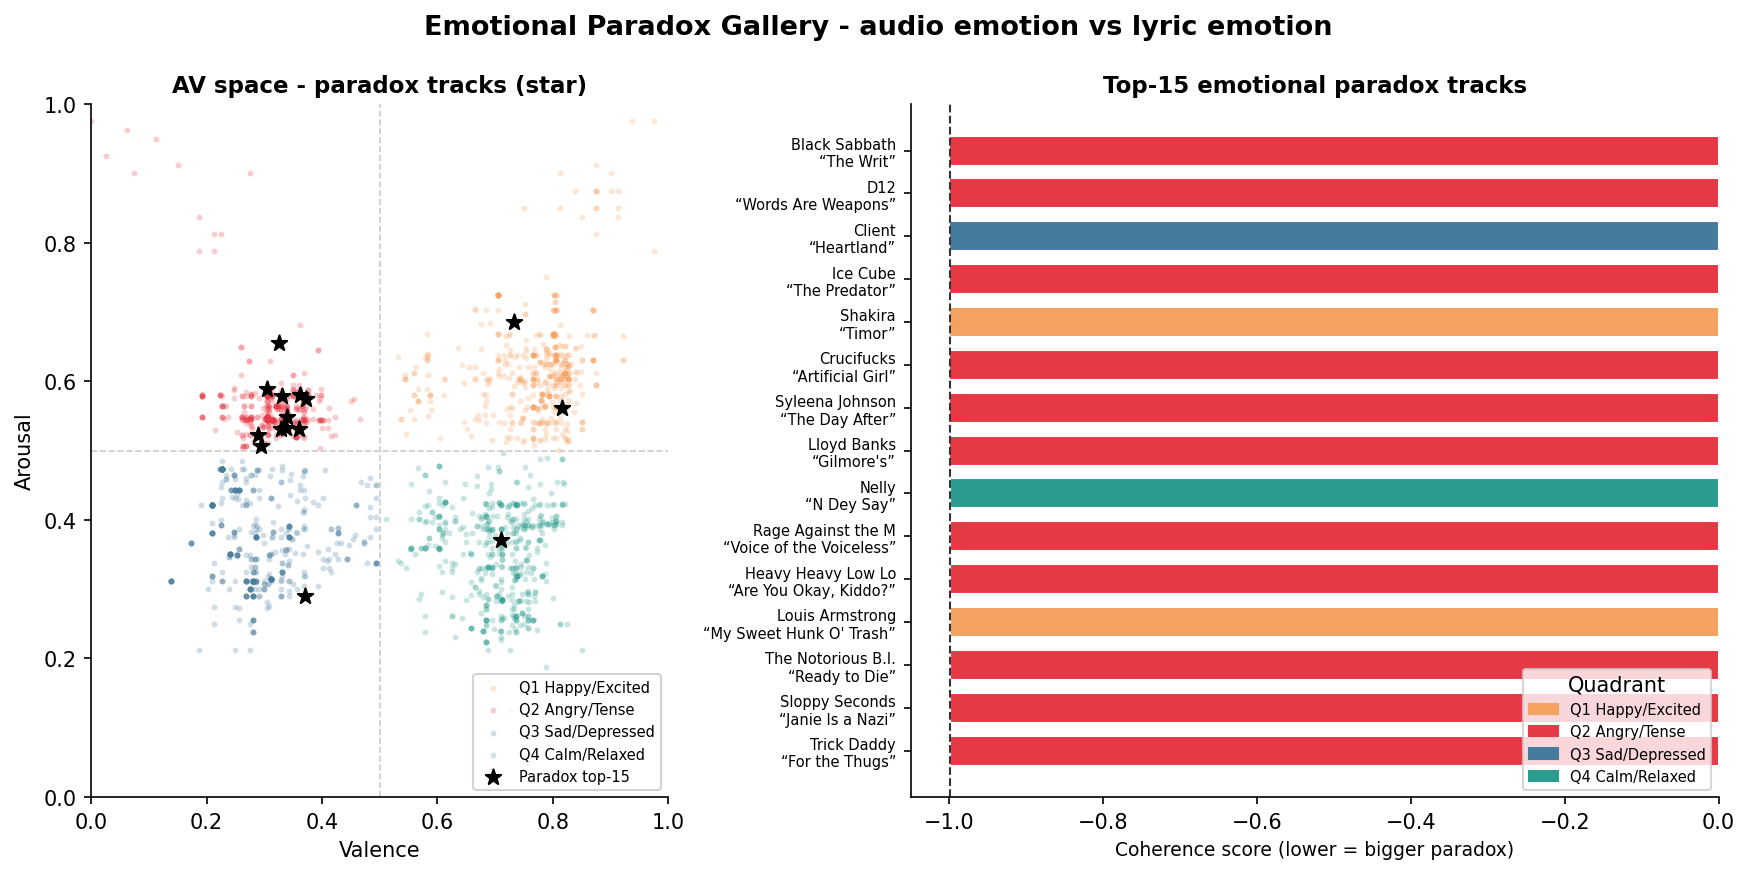

Saved paradox_gallery.png


In [46]:
# ── Figure: AV scatter with paradox tracks highlighted + bar chart ─────────
STR_Q = {'Q1': 1, 'Q2': 2, 'Q3': 3, 'Q4': 4}   # coh_df uses string quadrant labels
LQDQ  = chr(8220); RQDQ = chr(8221)              # left/right double quotation marks

fig = plt.figure(figsize=(14, 6))
gs  = gridspec.GridSpec(1, 2, width_ratios=[1, 1.4], figure=fig, wspace=0.35)

# --- left: AV scatter -------------------------------------------------------
ax_av = fig.add_subplot(gs[0])
for q in [1, 2, 3, 4]:
    mask = mm_df['quadrant'] == q
    ax_av.scatter(
        mm_df.loc[mask, 'valence'], mm_df.loc[mask, 'arousal'],
        c=Q_COLORS[q], s=8, alpha=0.25, linewidths=0, label=Q_LABELS[q]
    )
ax_av.scatter(
    paradox_df['valence'], paradox_df['arousal'],
    c='black', s=60, zorder=5, marker='*', label='Paradox top-15'
)
ax_av.axhline(0.5, color='#ccc', lw=0.8, ls='--')
ax_av.axvline(0.5, color='#ccc', lw=0.8, ls='--')
ax_av.set_xlabel('Valence', fontsize=10)
ax_av.set_ylabel('Arousal', fontsize=10)
ax_av.set_title('AV space - paradox tracks (star)', fontsize=11, fontweight='bold')
ax_av.legend(fontsize=7, loc='lower right', framealpha=0.85)
ax_av.set_xlim(0, 1); ax_av.set_ylim(0, 1)

# --- right: horizontal bar chart --------------------------------------------
ax_bar = fig.add_subplot(gs[1])
labels = [f"{row['artist'][:18]}\n{LQDQ}{row['title'][:22]}{RQDQ}"
          for _, row in paradox_df.iterrows()]
bar_colors = [Q_COLORS[STR_Q.get(str(q), 1)] for q in paradox_df['quadrant']]
ax_bar.barh(range(len(paradox_df)), paradox_df['coherence_score'],
            color=bar_colors, edgecolor='white', height=0.7)
ax_bar.set_yticks(range(len(paradox_df)))
ax_bar.set_yticklabels(labels, fontsize=7)
ax_bar.invert_yaxis()
ax_bar.set_xlabel('Coherence score (lower = bigger paradox)', fontsize=9)
ax_bar.set_title('Top-15 emotional paradox tracks', fontsize=11, fontweight='bold')
ax_bar.axvline(paradox_df['coherence_score'].mean(), color='#333', ls='--', lw=1)
patches = [mpatches.Patch(color=Q_COLORS[q], label=Q_LABELS[q]) for q in [1, 2, 3, 4]]
ax_bar.legend(handles=patches, fontsize=7, loc='lower right', title='Quadrant')

fig.suptitle('Emotional Paradox Gallery - audio emotion vs lyric emotion',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUTPUTS + r'\paradox_gallery.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved paradox_gallery.png')

  Q1 Happy/Excited: mean=0.463, std=0.594, n=509
  Q2 Angry/Tense: mean=0.328, std=0.750, n=583
  Q3 Sad/Depressed: mean=0.260, std=0.613, n=480
  Q4 Calm/Relaxed: mean=0.691, std=0.409, n=503


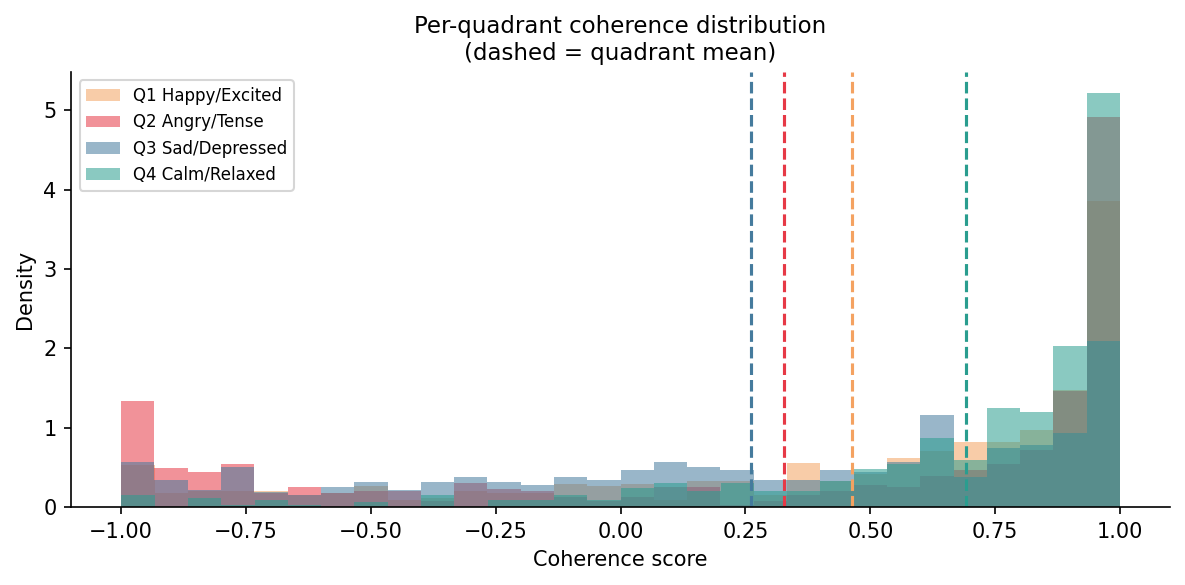

Saved coherence_per_quadrant.png


In [47]:
# ── Per-quadrant coherence distribution ──────────────────────────────────
# coh_df already has 'quadrant' column ('Q1'..'Q4') â€” no merge needed
STR_Q = {'Q1': 1, 'Q2': 2, 'Q3': 3, 'Q4': 4}

fig, ax = plt.subplots(figsize=(8, 4))
for qs in ['Q1', 'Q2', 'Q3', 'Q4']:
    vals = coh_df.loc[coh_df['quadrant'] == qs, 'coherence_score'].dropna()
    q    = STR_Q[qs]
    ax.hist(vals, bins=30, alpha=0.55, color=Q_COLORS[q], label=Q_LABELS[q], density=True)
    ax.axvline(vals.mean(), color=Q_COLORS[q], lw=1.5, ls='--')
    print(f"  {Q_LABELS[q]}: mean={vals.mean():.3f}, std={vals.std():.3f}, n={len(vals)}")

ax.set_xlabel('Coherence score', fontsize=10)
ax.set_ylabel('Density', fontsize=10)
ax.set_title('Per-quadrant coherence distribution\n(dashed = quadrant mean)', fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUTS + r'\coherence_per_quadrant.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved coherence_per_quadrant.png')

## 4  Ablation table (paper-ready)

In [48]:
print(abl_df.columns.tolist())
print(abl_df.head(10).to_string())

['Strategy', 'Split', 'K', 'Precision', 'AV_Dist', 'Diversity', 'Genre_Div']
      Strategy     Split   K  Precision  AV_Dist  Diversity  Genre_Div
0   audio_only  70/15/15   5      0.387    0.283      0.289      0.558
1   audio_only  70/15/15  10      0.380    0.284      0.290      0.565
2   audio_only  40/30/30   5      0.394    0.286      0.282      0.560
3   audio_only  40/30/30  10      0.386    0.287      0.285      0.564
4  lyrics_only  70/15/15   5      0.629    0.195      0.210      0.408
5  lyrics_only  70/15/15  10      0.608    0.201      0.216      0.414
6  lyrics_only  40/30/30   5      0.623    0.200      0.210      0.411
7  lyrics_only  40/30/30  10      0.604    0.207      0.218      0.418
8     late_0.2  70/15/15   5      0.636    0.195      0.213      0.414
9     late_0.2  70/15/15  10      0.621    0.200      0.215      0.413


In [49]:
# ── Build pivot: rows = strategy, cols = (split Ã— metric) ─────────────────
# Identify key columns
strategy_col = [c for c in abl_df.columns if 'strategy' in c.lower() or 'fusion' in c.lower()][0]
split_col    = [c for c in abl_df.columns if 'split' in c.lower()]
split_col    = split_col[0] if split_col else None

prec_col  = [c for c in abl_df.columns if 'prec' in c.lower() or 'precision' in c.lower()]
div_col   = [c for c in abl_df.columns if 'div' in c.lower()]
av_col    = [c for c in abl_df.columns if 'av_dist' in c.lower() or 'av dist' in c.lower()]
cold_col  = [c for c in abl_df.columns if 'cold' in c.lower()]

metric_cols = prec_col + av_col + div_col + cold_col
metric_cols = [c for c in metric_cols if c in abl_df.columns]

print('Strategy col :', strategy_col)
print('Split col    :', split_col)
print('Metric cols  :', metric_cols)

Strategy col : Strategy
Split col    : Split
Metric cols  : ['Precision', 'AV_Dist', 'Diversity', 'Genre_Div']


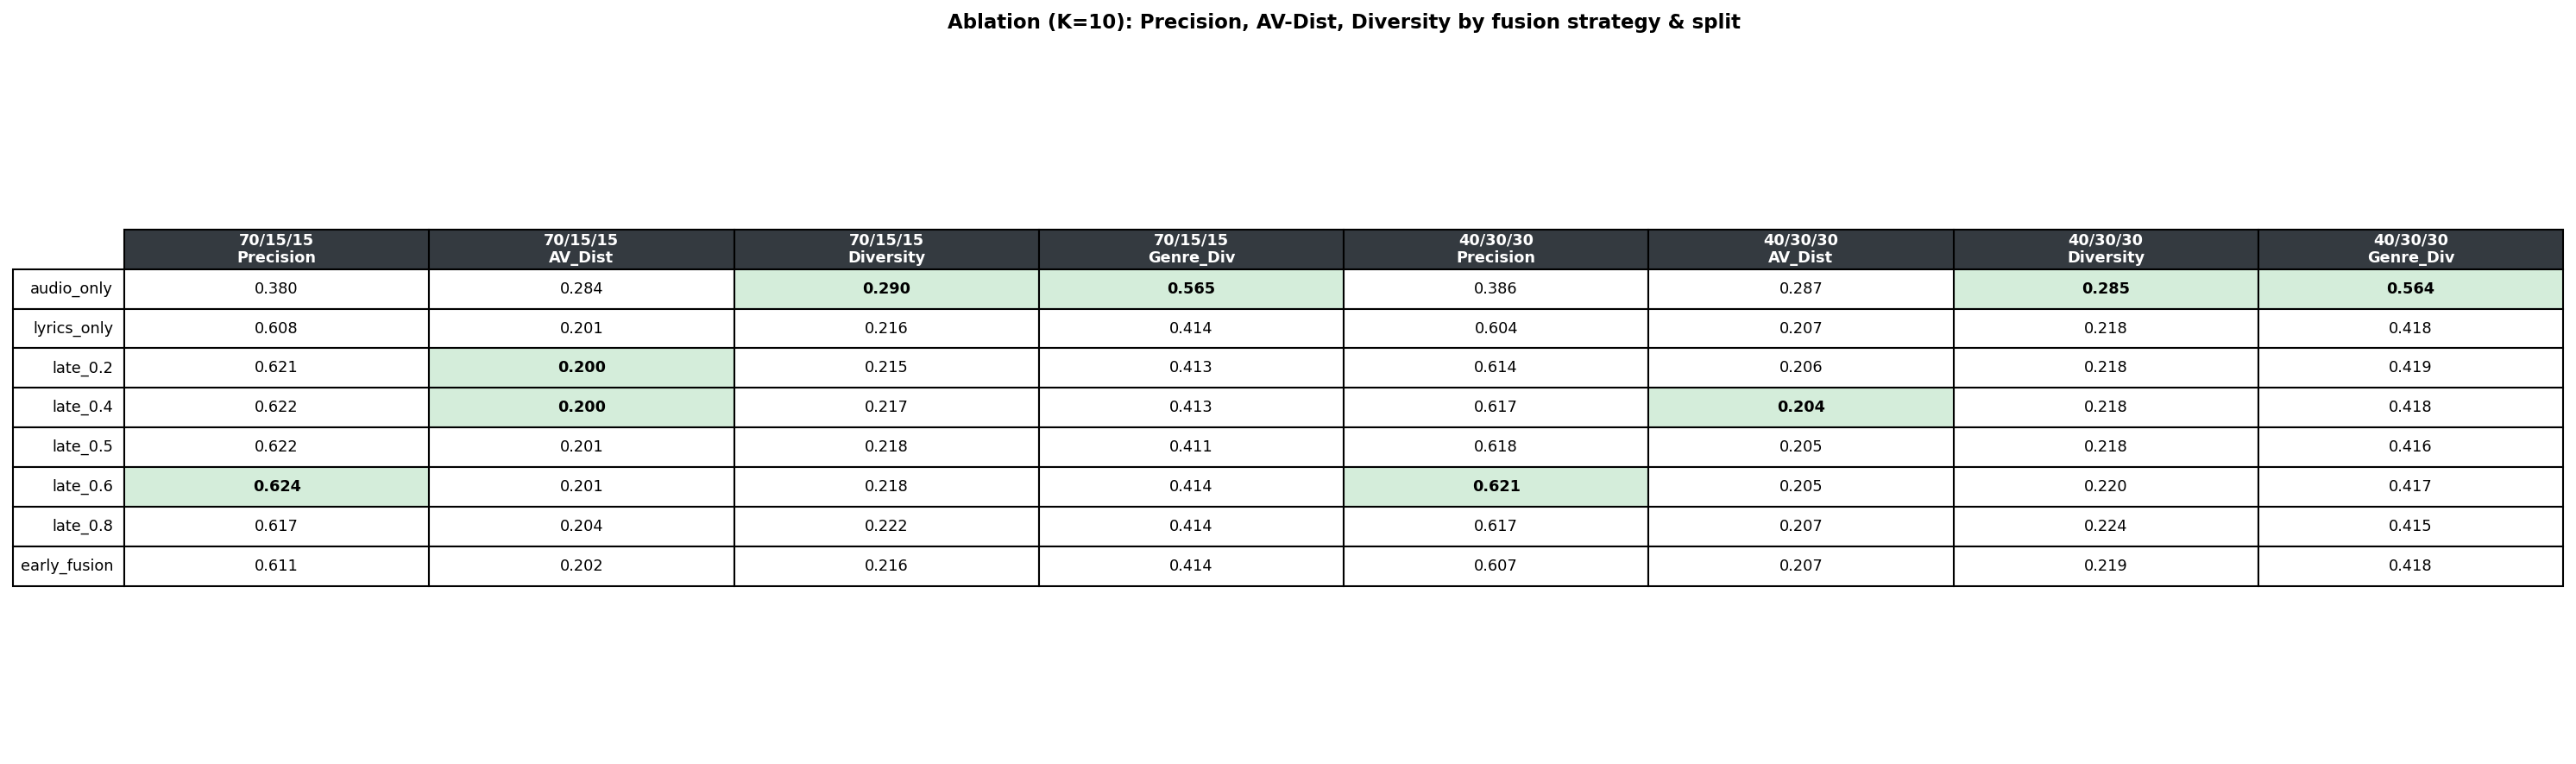

Saved ablation_table_figure.png


In [50]:
# ── Render matplotlib table ───────────────────────────────────────────────
import matplotlib.colors as mcolors

def render_ablation_table(df, strategy_col, split_col, metric_cols):
    strategies = df[strategy_col].unique().tolist()

    if split_col and split_col in df.columns:
        splits = df[split_col].unique().tolist()
        col_headers = [f"{s}\n{m}" for s in splits for m in metric_cols]
        n_cols = len(splits) * len(metric_cols)
        table_data = []
        for strat in strategies:
            row = []
            for sp in splits:
                sub = df[(df[strategy_col] == strat) & (df[split_col] == sp)]
                for m in metric_cols:
                    if len(sub) and m in sub.columns:
                        row.append(f"{sub[m].values[0]:.3f}")
                    else:
                        row.append('â€”')
            table_data.append(row)
    else:
        col_headers = metric_cols
        n_cols = len(metric_cols)
        table_data = []
        for strat in strategies:
            sub = df[df[strategy_col] == strat]
            row = []
            for m in metric_cols:
                if len(sub) and m in sub.columns:
                    row.append(f"{sub[m].values[0]:.3f}")
                else:
                    row.append('â€”')
            table_data.append(row)

    n_rows = len(strategies)

    fig, ax = plt.subplots(figsize=(max(8, 2.5 * n_cols), 0.6 * (n_rows + 2)))
    ax.axis('off')

    tbl = ax.table(
        cellText=table_data,
        rowLabels=strategies,
        colLabels=col_headers,
        cellLoc='center',
        rowLoc='right',
        loc='center',
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8.5)
    tbl.scale(1, 1.6)

    # highlight best per column (green = best; AV_Dist: lower is better)
    low_cols = [i for i, h in enumerate(col_headers) if 'av_dist' in h.lower()]
    for ci in range(n_cols):
        numeric_vals = []
        for row in table_data:
            try:
                numeric_vals.append(float(row[ci]))
            except ValueError:
                numeric_vals.append(None)
        valid = [v for v in numeric_vals if v is not None]
        if not valid:
            continue
        best = min(valid) if ci in low_cols else max(valid)
        for ri, v in enumerate(numeric_vals):
            if v == best:
                tbl[ri + 1, ci].set_facecolor('#d4edda')
                tbl[ri + 1, ci].set_text_props(fontweight='bold')

    # dark header row
    for ci in range(n_cols):
        tbl[0, ci].set_facecolor('#343a40')
        tbl[0, ci].set_text_props(color='white', fontweight='bold')

    ax.set_title('Ablation (K=10): Precision, AV-Dist, Diversity by fusion strategy & split',
                 fontsize=11, fontweight='bold', pad=20)
    plt.tight_layout()
    return fig

# filter to K=10 rows only
abl_K10 = abl_df[abl_df['K'] == 10].copy()
fig = render_ablation_table(abl_K10, strategy_col, split_col, metric_cols)
fig.savefig(OUTPUTS + r'\ablation_table_figure.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved ablation_table_figure.png')

## 5  Precision@K curves (paper quality)

In [51]:
# Load 70/15/15 test split directly
SPLIT_TEST = (ROOT + r'\MERGE_Audio_Balanced\tvt_dataframes'
              r'\tvt_70_15_15\tvt_70_15_15_test_audio_balanced.csv')
test_split = pd.read_csv(SPLIT_TEST)
print(f'Test split: {test_split.shape}  columns: {test_split.columns.tolist()}')
print(test_split.head(3))

Test split: (484, 2)  columns: ['Song', 'Quadrant']
           Song Quadrant
0  MT0031693432       Q3
1  MT0000661250       Q3
2  MT0002915967       Q3


In [52]:
# Intersect test-split song IDs with multimodal tracks
test_sids = sorted(set(test_split['Song'].astype(str)) & set(mm_sids))
print(f'Test-set multimodal tracks: {len(test_sids)}')

Test-set multimodal tracks: 397


In [53]:
# Load FAISS indices
audio_index = faiss.read_index(FAISS_DIR + r'\audio_only.index')
audio_meta  = pd.read_parquet(FAISS_DIR + r'\audio_only_meta.parquet')
audio_sid   = audio_meta['song_id'].tolist()

lyrics_index = faiss.read_index(FAISS_DIR + r'\lyrics_only.index')
lyrics_meta  = pd.read_parquet(FAISS_DIR + r'\lyrics_only_meta.parquet')
lyrics_sid   = lyrics_meta['song_id'].tolist()

# early_index already loaded above

# Build normalized audio and lyrics arrays for mm tracks
mm_clap_normed  = np.vstack([clap_arr[audio_sid_idx[s]] for s in mm_sids]).astype(np.float32)
mm_sbert_normed = np.vstack([sbert_arr[lyrics_sid_idx[s]] for s in mm_sids]).astype(np.float32)

mm_sid_idx = {sid: i for i, sid in enumerate(mm_sids)}
quad_map   = meta_df.set_index('song_id')['quadrant'].to_dict()

# Build index-level sid lists for retrieval
audio_idx_map  = {sid: i for i, sid in enumerate(audio_sid)}
lyrics_idx_map = {sid: i for i, sid in enumerate(lyrics_sid)}
early_idx_map  = {sid: i for i, sid in enumerate(early_sid)}

print('All indices loaded.')

All indices loaded.


In [54]:
K_VALUES = [1, 2, 3, 5, 10, 15, 20]
K_MAX    = max(K_VALUES)
ALPHA    = 0.4   # best late-fusion alpha from ablation

def precision_at_k(retrieved_sids, query_quad, k):
    hits = sum(1 for s in retrieved_sids[:k] if quad_map.get(s) == query_quad)
    return hits / k

strategies = {
    'audio_only' : [],
    'lyrics_only': [],
    f'late_{ALPHA}' : [],
    'early_fusion': [],
}

for q_sid in test_sids:
    q_quad = quad_map[q_sid]
    mi = mm_sid_idx[q_sid]

    # audio-only
    qv = mm_clap_normed[mi:mi+1]
    _, I = audio_index.search(qv, K_MAX + 10)
    ret = [audio_sid[j] for j in I[0] if audio_sid[j] != q_sid][:K_MAX]
    strategies['audio_only'].append([precision_at_k(ret, q_quad, k) for k in K_VALUES])

    # lyrics-only
    qv = mm_sbert_normed[mi:mi+1]
    _, I = lyrics_index.search(qv, K_MAX + 10)
    ret = [lyrics_sid[j] for j in I[0] if lyrics_sid[j] != q_sid][:K_MAX]
    strategies['lyrics_only'].append([precision_at_k(ret, q_quad, k) for k in K_VALUES])

    # early fusion
    qv = mm_early_normed[mi:mi+1]
    _, I = early_index.search(qv, K_MAX + 10)
    ret = [early_sid[j] for j in I[0] if early_sid[j] != q_sid][:K_MAX]
    strategies['early_fusion'].append([precision_at_k(ret, q_quad, k) for k in K_VALUES])

    # late fusion — weighted combination of cosine similarities
    audio_sims  = np.dot(mm_clap_normed,  mm_clap_normed[mi])   # (N,)
    lyrics_sims = np.dot(mm_sbert_normed, mm_sbert_normed[mi])
    fused_sims  = ALPHA * audio_sims + (1 - ALPHA) * lyrics_sims
    fused_sims[mi] = -1   # exclude self
    top_idx = np.argsort(-fused_sims)[:K_MAX]
    ret = [mm_sids[j] for j in top_idx]
    strategies[f'late_{ALPHA}'].append([precision_at_k(ret, q_quad, k) for k in K_VALUES])

# Average across queries
mean_prec = {}
for strat, rows in strategies.items():
    arr = np.array(rows)  # (n_queries, n_k)
    mean_prec[strat] = arr.mean(axis=0)

print('Precision@K computed for', len(test_sids), 'test queries')
for strat, vals in mean_prec.items():
    print(f'  {strat:20s}  ' + '  '.join(f'@{k}={v:.3f}' for k, v in zip(K_VALUES, vals)))


Precision@K computed for 397 test queries
  audio_only            @1=0.418  @2=0.414  @3=0.402  @5=0.387  @10=0.380  @15=0.377  @20=0.375
  lyrics_only           @1=0.665  @2=0.651  @3=0.639  @5=0.629  @10=0.608  @15=0.600  @20=0.593
  late_0.4              @1=0.665  @2=0.671  @3=0.665  @5=0.642  @10=0.622  @15=0.610  @20=0.609
  early_fusion          @1=0.670  @2=0.659  @3=0.647  @5=0.631  @10=0.611  @15=0.600  @20=0.595


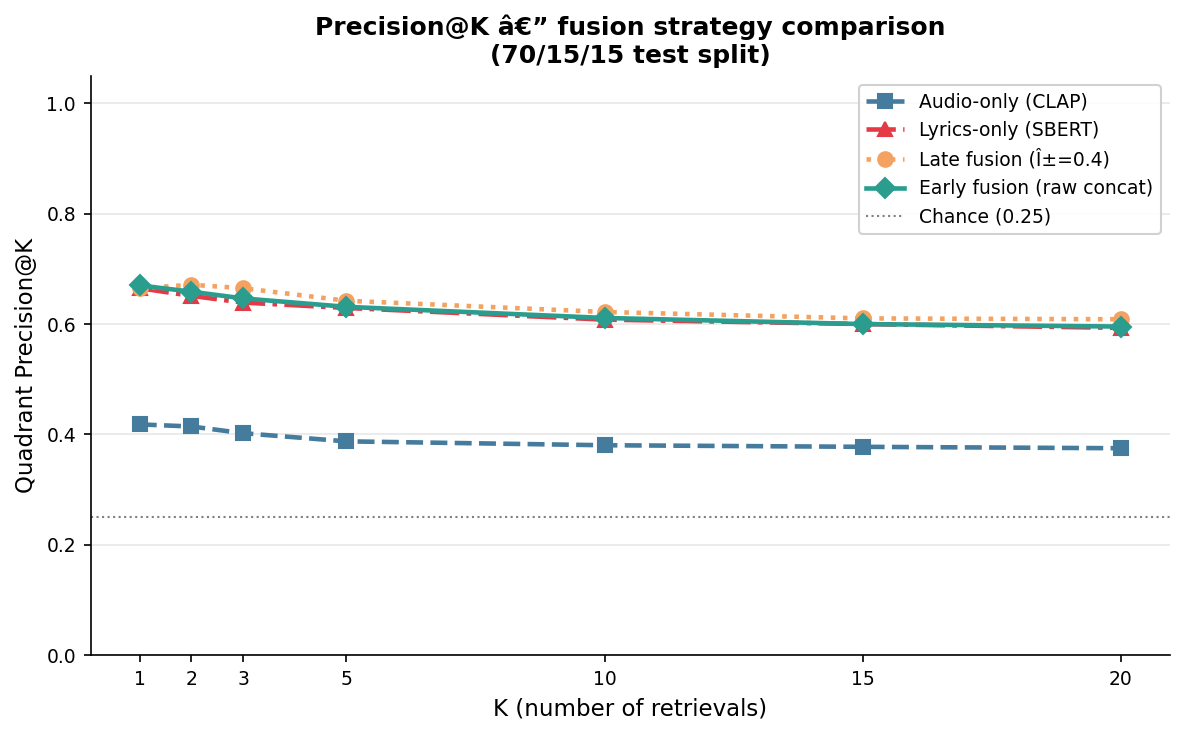

Saved precision_at_k_curves.png


In [ ]:
# ── Precision@K curves (paper-quality) ────────────────────────────────────
STRAT_STYLE = {
    'audio_only'        : dict(color='#457B9D', ls='--',  marker='s', label='Audio-only (CLAP)'),
    'lyrics_only'       : dict(color='#E63946', ls='-.',  marker='^', label='Lyrics-only (SBERT)'),
    f'late_{ALPHA}'     : dict(color='#F4A261', ls=':',   marker='o', label=f'Late fusion (Î±={ALPHA})'),
    'early_fusion'      : dict(color='#2A9D8F', ls='-',   marker='D', label='Early fusion (raw concat)'),
}

fig, ax = plt.subplots(figsize=(8, 5))

for strat, style in STRAT_STYLE.items():
    if strat not in mean_prec:
        continue
    ax.plot(K_VALUES, mean_prec[strat],
            color=style['color'], ls=style['ls'],
            marker=style['marker'], ms=7, lw=2.2,
            label=style['label'])

ax.set_xlabel('K (number of retrievals)', fontsize=11)
ax.set_ylabel('Quadrant Precision@K', fontsize=11)
ax.set_title('Precision@K fusion strategy comparison\n(70/15/15 test split)', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='upper right', framealpha=0.9)
ax.set_xticks(K_VALUES)
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)
ax.tick_params(labelsize=9)

# chance baseline
ax.axhline(0.25, color='grey', ls=':', lw=1, label='Chance (0.25)')
ax.legend(fontsize=9, loc='upper right', framealpha=0.9)

plt.tight_layout()
fig.savefig(OUTPUTS + r'\precision_at_k_curves.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved precision_at_k_curves.png')

## 6  Summary statistics table

In [57]:
# ── Per-quadrant coherence summary ────────────────────────────────────────
# coh_df already has quadrant as 'Q1'..'Q4' strings
coh_summary = (
    coh_df.groupby('quadrant')['coherence_score']
    .agg(['mean', 'std', 'median', 'min', 'max'])
    .round(3)
    .rename(index={'Q1': 'Q1 Happy', 'Q2': 'Q2 Angry', 'Q3': 'Q3 Sad', 'Q4': 'Q4 Calm'})
)
print('Coherence by quadrant:')
print(coh_summary.to_string())

print('Top-15 paradox tracks:')
print(paradox_df[['artist', 'title', 'quadrant', 'coherence_score']].to_string(index=False))

print('Precision@K summary:')
for strat, vals in mean_prec.items():
    print(f'  {strat:20s}  @5={vals[K_VALUES.index(5)]:.3f}  @10={vals[K_VALUES.index(10)]:.3f}  @20={vals[K_VALUES.index(20)]:.3f}')


Coherence by quadrant:
           mean    std  median    min  max
quadrant                                  
Q1 Happy  0.463  0.594   0.705 -1.000  1.0
Q2 Angry  0.328  0.750   0.754 -1.000  1.0
Q3 Sad    0.260  0.613   0.404 -1.000  1.0
Q4 Calm   0.691  0.409   0.855 -0.999  1.0
Top-15 paradox tracks:
                  artist                  title quadrant  coherence_score
           Black Sabbath               The Writ       Q2        -0.999999
                     D12      Words Are Weapons       Q2        -0.999955
                  Client              Heartland       Q3        -0.999924
                Ice Cube           The Predator       Q2        -0.999805
                 Shakira                  Timor       Q1        -0.999802
              Crucifucks        Artificial Girl       Q2        -0.999772
         Syleena Johnson          The Day After       Q2        -0.999649
             Lloyd Banks              Gilmore's       Q2        -0.999641
                   Nelly      

## Done

**Outputs saved:**
- `outputs/umap_joint_space.png` â€” UMAP of 2,075 tracks in early-fusion space
- `outputs/cross_genre_gallery.png` â€” same-quadrant cross-genre twin pairs
- `outputs/paradox_gallery.png` â€” top-15 lowest-coherence tracks (AV scatter + bar)
- `outputs/coherence_per_quadrant.png` â€” per-quadrant coherence distributions
- `outputs/ablation_table_figure.png` â€” paper-ready ablation table
- `outputs/precision_at_k_curves.png` â€” Precision@K for all fusion strategies